# Test the wake-word models with your microphone (ONNX, local)

Record from your **computer's microphone** and see how one or several **ONNX** models react to "hey tara", to near-miss words ("hey cara", "hey terra", ...) and to ordinary speech. This is the ONNX twin of `mic_test_models_local.ipynb`: same preprocessing, same detector, same plots, but the networks run in **ONNX Runtime**, so **PyTorch is not needed**.

**What you need:** one or more `.onnx` files in the local `./onnx_models/` folder. Create them from your `.pt` checkpoints with

```
python convert_to_onnx.py            # ./model/*.pt  ->  ./onnx_models/*.onnx
```

Each `.onnx` file carries its own thresholds (`far1pct`, `far0.1pct`), so nothing else has to be uploaded. The two small helper pieces of the original package (the feature extractor and the `stats.json` mean/std) are embedded below.

**The preprocessing (identical to training):**
1. decode to 16 kHz mono;
2. find the **active speech frames** (frames within 35 dB of the loudest frame and above -60 dB);
3. scale so the active speech has an RMS of **-20 dBFS** (the level of every training clip), then peak-limit at 0.95;
4. cut a rolling **3 s buffer** into five overlapping **2 s windows** (0.25 s steps);
5. **log-mel features**: 25 ms Hann frames, 10 ms hop, 512-point FFT, 40 mel bins in dB (201 frames per window);
6. **standardise** every mel bin with the package `stats.json`;
7. model (ONNX), then sigmoid. The buffer score is the **maximum** over its five windows.

**Detector rules:** a silence gate (a buffer whose loudest frame is below -50 dB scores 0), a score above the threshold fires, then a 3 s cool-down so one utterance fires once.

**Why the level matters:** normalisation removes the *loudness* of your voice but not the *noise*: a quiet recording is amplified together with its background noise, and the model sees a noisier clip. Record at a normal distance, in a reasonably quiet room, without clipping. The notebook checks this for you.

## 1. Setup
Runs fully locally. Install the dependencies once (no PyTorch):

```
pip install onnxruntime numpy pandas matplotlib soundfile sounddevice scipy
```
Launch the notebook from the folder that contains `onnx_models/`.

In [2]:
import os, sys, json, math, warnings, glob, time
from pathlib import Path
from types import SimpleNamespace
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import onnxruntime as ort
from scipy.fft import rfft
from IPython.display import display, Audio
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200, "display.max_columns", None)

# ---- feature extractor: the same numpy/scipy code as the training package (heytara_prep), reduced to what inference needs ----
SR = 16000
WIN_S = 2.0; WIN = int(SR * WIN_S)                                  # model window: 2 s = 32000 samples
HOP, N_FFT, WIN_LEN, FMIN, FMAX = 160, 512, 400, 20.0, 7600.0
N_MELS = 40; N_FRAMES = 1 + WIN // HOP                              # 40 mels x 201 frames
TARGET_RMS_DB, PEAK_LIMIT = -20.0, 0.95
TRIM_REL_DB, TRIM_ABS_DB = 35.0, -60.0
MEL_CHUNK = 128

def frame_db(x, frame=HOP):
    n = len(x) // frame
    if n == 0: return np.array([-120.0])
    f = x[: n * frame].reshape(n, frame)
    return 10 * np.log10(np.mean(f.astype(np.float64) ** 2, axis=1) + 1e-12)

def _mel_filterbank():                                              # HTK-scale triangular filterbank, (N_FFT//2+1, N_MELS)
    hz2mel = lambda f: 2595.0 * np.log10(1.0 + f / 700.0)
    mel2hz = lambda m: 700.0 * (10.0 ** (m / 2595.0) - 1.0)
    freqs = np.linspace(0, SR / 2, N_FFT // 2 + 1)
    pts = mel2hz(np.linspace(hz2mel(FMIN), hz2mel(FMAX), N_MELS + 2))
    slopes = pts[None, :] - freqs[:, None]
    down = -slopes[:, :-2] / np.diff(pts)[:-1]; up = slopes[:, 2:] / np.diff(pts)[1:]
    return np.maximum(0.0, np.minimum(down, up)).astype(np.float32)

_FB = _mel_filterbank()
_STFT_WIN = np.zeros(N_FFT, np.float32)                             # periodic Hann of length WIN_LEN, centred in the FFT frame
_STFT_WIN[(N_FFT - WIN_LEN) // 2:(N_FFT - WIN_LEN) // 2 + WIN_LEN] = 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(WIN_LEN) / WIN_LEN)
_FRAME_IDX = np.arange(N_FRAMES)[:, None] * HOP + np.arange(N_FFT)[None, :]

def log_mel_db(wins):                                               # (B, WIN) float32 -> (B, N_MELS, N_FRAMES) dB float32
    wins = np.asarray(wins, np.float32)
    out = np.empty((len(wins), N_MELS, N_FRAMES), np.float32)
    for a in range(0, len(wins), MEL_CHUNK):
        x = np.pad(wins[a:a + MEL_CHUNK], ((0, 0), (N_FFT // 2, N_FFT // 2)), mode="reflect")
        frames = x[:, _FRAME_IDX] * _STFT_WIN
        spec = rfft(frames, axis=-1)
        mel = np.matmul(spec.real ** 2 + spec.imag ** 2, _FB)
        out[a:a + MEL_CHUNK] = (10 * np.log10(np.maximum(mel, 1e-10))).transpose(0, 2, 1)
    return out

P = SimpleNamespace(SR=SR, WIN_S=WIN_S, WIN=WIN, HOP=HOP, N_MELS=N_MELS, N_FRAMES=N_FRAMES, TARGET_RMS_DB=TARGET_RMS_DB,
                    PEAK_LIMIT=PEAK_LIMIT, TRIM_REL_DB=TRIM_REL_DB, TRIM_ABS_DB=TRIM_ABS_DB, frame_db=frame_db, log_mel_db=log_mel_db)

# ---- per-mel-bin standardisation (stats.json of the package, embedded) ----
STATS = json.loads('''{"mean":[-16.39230405908544,-17.77997113391565,-16.580688469082443,-16.44016175791798,-17.071640658493813,-17.589673243932637,-17.94564574832863,-18.129610251487744,-17.82021747440494,-18.467185583039132,-18.383016774793703,-19.13317845904737,-19.43265498333003,-19.67478662971602,-19.737176728976433,-19.933943827667076,-19.70702139962237,-19.63523263117948,-19.719363361534466,-19.89471676156216,-20.093854390258254,-20.272418230422286,-20.284327593514163,-20.147958768318762,-20.0691517456691,-20.06100748769435,-20.222173668565652,-20.397828321281697,-20.55934901866008,-20.720946951308505,-20.930816004644463,-21.250846016961695,-21.656388168156564,-22.190140366953592,-22.49169258399409,-22.722827632155774,-22.926628629756785,-22.781706973066246,-22.412472955517433,-22.253731814906594],"std":[26.403883789679963,25.64724607600804,26.1985847931721,26.237583000376254,25.637831553473244,25.162260075148595,24.952045912888256,24.822137275521758,24.74171444759984,24.45650722207447,24.08707405180526,23.45340930899279,22.947800650387713,22.62042240554014,22.380601799004282,22.259668852165593,22.247859870415294,22.106076845844033,21.813092531294092,21.528330213948426,21.23748252955553,21.010334425162828,20.890048914700238,20.859505447246953,20.86410209069722,20.793384052429182,20.504198283876928,20.152315963819024,19.854027076015004,19.590961230195127,19.369781899169798,19.125082958910625,18.831893188315217,18.524103523291746,18.323028789648053,18.18502030532703,18.082277103541884,18.04238794243285,17.9284823916813,17.85190401724732]}''')
MEAN = np.asarray(STATS["mean"], np.float32).reshape(1, -1, 1); STD = np.asarray(STATS["std"], np.float32).reshape(1, -1, 1)
print(f"setup done | onnxruntime {ort.__version__} | {P.N_MELS} mels x {P.N_FRAMES} frames per {P.WIN_S:.0f} s window | target level {P.TARGET_RMS_DB} dBFS")

setup done | onnxruntime 1.31.1 | 40 mels x 201 frames per 2 s window | target level -20.0 dBFS


## 2. Load the ONNX models
Every `.onnx` model found in the local **`./onnx_models/`** folder (e.g. `./onnx_models/matchboxnet_finetuned.onnx`; subfolders are searched too) is listed. Change `ONNX_DIR` if your folder is elsewhere. **Choose which to test** by editing `USE` (a list of name fragments; an empty list means all). Each model uses the thresholds stored inside its file: `far1pct` (about 1% false accepts) is the default; `far0.1pct` is stricter.

`PROVIDERS` selects the ONNX Runtime backend. CPU is plenty for these small models; add `"CUDAExecutionProvider"` first if you installed `onnxruntime-gpu`.

In [3]:
THR_KEY = "far1pct"                                          # "far1pct" (default) or "far0.1pct" (stricter, fewer false alarms, more misses)
USE = []                                                     # e.g. ["matchboxnet_finetuned", "tc_resnet"]; empty = every model found

ONNX_DIR = Path("./onnx_models")                             # local folder holding your models: ./onnx_models/<model_name>.onnx
PROVIDERS = ["CPUExecutionProvider"]                         # e.g. ["CUDAExecutionProvider", "CPUExecutionProvider"]
N_THREADS = 2

def find_models():
    # every .onnx under the local ./onnx_models folder (subfolders included)
    env = os.environ.get("HEYTARA_ONNX_MODELS")                                      # (testing) path list separated by ;
    cands = [Path(p) for p in env.split(";")] if env else [Path(p) for p in glob.glob(str(ONNX_DIR / "**" / "*.onnx"), recursive=True)]
    seen, out = set(), []
    for p in cands:
        key = p.resolve()
        if key in seen: continue
        seen.add(key); out.append(p)
    return sorted(out)

paths = find_models()
if USE: paths = [p for p in paths if any(u in p.stem or u in p.parent.name for u in USE)]
assert paths, f"no model file found: put your .onnx file(s) in {ONNX_DIR.resolve()} (create them with: python convert_to_onnx.py)"

_avail = ort.get_available_providers()
_prov = [p for p in PROVIDERS if p in _avail] or ["CPUExecutionProvider"]
_so = ort.SessionOptions(); _so.intra_op_num_threads = N_THREADS; _so.log_severity_level = 3

MODELS = {}
_stems = [p.stem for p in paths]
def label(p): return p.stem if _stems.count(p.stem) == 1 else f"{p.parent.name}/{p.stem}"
for p in paths:
    try:
        sess = ort.InferenceSession(str(p), _so, providers=_prov)
        inp, outp = sess.get_inputs()[0], sess.get_outputs()[0]
        shp = inp.shape                                                               # [batch, 1, n_mels, n_frames]
        assert shp[2] == P.N_MELS and shp[3] == P.N_FRAMES, f"model expects input {shp}, this notebook feeds (B, 1, {P.N_MELS}, {P.N_FRAMES})"
        meta = sess.get_modelmeta().custom_metadata_map
        thr = {k: float(v) for k, v in json.loads(meta.get("thresholds", "{}")).items()}
        MODELS[label(p)] = dict(sess=sess, inp=inp.name, out=outp.name, thr=thr.get(THR_KEY, 0.9), all_thr=thr, arch=meta.get("arch", "?"))
        print(f"loaded {label(p):34s} {meta.get('arch', '?'):12s} {p.stat().st_size / 1024:6.0f} KB | thresholds {({k: round(v, 3) for k, v in thr.items()})} | {meta.get('threshold_note', '')[:60]}")
    except Exception as e:
        print(f"skipped {p}: {type(e).__name__}: {str(e)[:100]}")
assert MODELS, "none of the files could be loaded as an ONNX wake-word model"
print("\nin use:", {n: round(m['thr'], 3) for n, m in MODELS.items()}, f"(threshold = {THR_KEY}; edit MODELS[name]['thr'] to tune one) | providers {_prov}")

loaded matchboxnet_finetuned              matchboxnet     475 KB | thresholds {'far1pct': 0.789, 'far0.1pct': 0.942} | REAL-calibrated: FAR 1% / 0.1% on out-of-fold real training 
loaded tc_resnet_finetuned                tc_resnet      1915 KB | thresholds {'far1pct': 0.845, 'far0.1pct': 0.973} | REAL-calibrated: FAR 1% / 0.1% on out-of-fold real training 

in use: {'matchboxnet_finetuned': 0.789, 'tc_resnet_finetuned': 0.845} (threshold = far1pct; edit MODELS[name]['thr'] to tune one) | providers ['CPUExecutionProvider']


## 3. Preprocessing and the detector
`preprocess()` returns every intermediate so it can be inspected; the **detector** feeds the recording in 0.1 s pieces through a rolling 3 s buffer and scores it every 0.25 s, as a deployed detector would. `level_report()` checks your recording against the problems found on real data: too quiet (the normalisation amplifies noise), clipped, or a high noise floor.

In [4]:
GATE_DB, HOP_S, BUF_S = -50.0, 0.25, 3.0
REFRACTORY_S = BUF_S                                              # one utterance stays in the 3 s buffer for up to 3 s: wait that long before firing again
STARTS = list(range(0, int(BUF_S * P.SR) - P.WIN + 1, int(0.25 * P.SR)))

def run_net(name, x):
    # x: (B, 1, 40, 201) float32 standardised log-mel -> sigmoid scores (B,)  [ONNX Runtime]
    m = MODELS[name]
    logit = m["sess"].run([m["out"]], {m["inp"]: np.ascontiguousarray(x, dtype=np.float32)})[0].astype(np.float64)
    return 1.0 / (1.0 + np.exp(-logit))

def preprocess(y):
    # one 3 s buffer -> dict of every step (or None if the silence gate blocks it)
    db = P.frame_db(y); mx = float(db.max())
    if mx < GATE_DB: return None
    act = db > max(mx - P.TRIM_REL_DB, P.TRIM_ABS_DB)                                         # active speech frames
    act_rms = 10 * np.log10(np.mean(10 ** (db[act] / 10)) + 1e-12); gain = P.TARGET_RMS_DB - act_rms
    z = y * 10 ** (gain / 20); limited = bool(np.abs(z).max() > P.PEAK_LIMIT)
    if limited: z = z * (P.PEAK_LIMIT / np.abs(z).max())
    wins = np.stack([z[s:s + P.WIN] for s in STARTS]).astype(np.float32)
    feats = P.log_mel_db(wins); x = ((feats - MEAN) / STD)[:, None].astype(np.float32)        # (5, 1, 40, 201), standardised per mel bin
    return dict(db=db, act=act, act_rms=act_rms, gain=gain, norm=z, wins=wins, mel_db=feats, x=x, limited=limited)

def score_buffer(y, name):
    pp = preprocess(y)
    return 0.0 if pp is None else float(run_net(name, pp["x"]).max())

class Detector:
    def __init__(self, name, thr=None):
        self.name, self.thr = name, MODELS[name]["thr"] if thr is None else thr
        self.hop = int(HOP_S * P.SR); self.buf = np.zeros(int(BUF_S * P.SR), np.float32); self.n = 0; self.since = 0; self.last = -1e9

    def feed(self, x):
        x = np.asarray(x, np.float32).reshape(-1); out = []; pos = 0
        while pos < len(x):
            take = min(len(x) - pos, self.hop - self.since); self.buf = np.concatenate([self.buf[take:], x[pos:pos + take]]); self.n += take; self.since += take; pos += take
            if self.since >= self.hop:
                self.since = 0; t = self.n / P.SR; warm = self.n < P.WIN
                s = 0.0 if warm else score_buffer(self.buf, self.name)
                ev = (not warm) and s > self.thr and (t - self.last) >= REFRACTORY_S
                if ev: self.last = t
                out.append(dict(t=t, score=s, event=bool(ev)))
        return out

def run_detector(audio, name):
    det = Detector(name); padded = np.concatenate([audio, np.zeros(int(0.5 * P.SR), np.float32)]); recs = []
    for i in range(0, len(padded), 1600): recs += det.feed(padded[i:i + 1600])
    return pd.DataFrame(recs)

def level_report(audio):
    lvl = P.frame_db(audio); pk = 20 * np.log10(np.abs(audio).max() + 1e-9); loud = float(lvl.max()); floor = float(np.percentile(lvl, 10))
    act = lvl > max(loud - P.TRIM_REL_DB, P.TRIM_ABS_DB); act_rms = float(10 * np.log10(np.mean(10 ** (lvl[act] / 10)) + 1e-12)); gain = P.TARGET_RMS_DB - act_rms; snr = act_rms - floor
    clip = float((np.abs(audio) > 0.99).mean()); notes = []
    if loud < GATE_DB + 6: notes.append("TOO QUIET: the silence gate blocks audio whose loudest frame is below %d dB; speak closer or louder" % GATE_DB)
    elif gain > 25: notes.append(f"QUIET: normalisation adds {gain:.0f} dB, which also amplifies the background noise; move closer to the microphone")
    if clip > 1e-4: notes.append(f"CLIPPING ({clip * 100:.2f}% of samples at full scale): speak softer or move back; clipping distorts the word")
    if snr < 8: notes.append(f"NOISY: speech is only {snr:.0f} dB above the background; the model sees a noisy clip (it was trained down to about 0 dB, but accuracy falls)")
    if not notes: notes.append("OK")
    return dict(peak_dBFS=float(pk), speech_rms_dB=act_rms, background_dB=floor, snr_dB=snr, gain_applied_dB=gain, clipped_pct=clip * 100, verdict=" | ".join(notes))

COLORS = plt.rcParams["axes.prop_cycle"].by_key()["color"]
def analyse(audio, name="recording", show_prep=True):
    audio = np.asarray(audio, np.float32).reshape(-1); lr = level_report(audio)
    print("level check:", {k: (round(v, 1) if not isinstance(v, str) else v) for k, v in lr.items() if k != "verdict"}); print("-> " + lr["verdict"])
    t0 = time.perf_counter(); R = {n: run_detector(audio, n) for n in MODELS}; dt = time.perf_counter() - t0
    print(f"detector run (all models, ONNX Runtime): {dt:.2f} s for {len(audio) / P.SR:.1f} s of audio")
    fig, ax = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True); ta = np.arange(len(audio)) / P.SR
    ax[0].plot(ta[::20], audio[::20], lw=.5, c="gray"); ax[0].set_title(f"{name}: {len(audio) / P.SR:.1f} s, peak {lr['peak_dBFS']:.0f} dBFS (raw, before normalisation)"); ax[0].set_ylabel("amplitude")
    for k, (n, r) in enumerate(R.items()):
        c = COLORS[k % len(COLORS)]; ax[1].plot(r.t, r.score, c=c, label=f"{n} (thr {MODELS[n]['thr']:.2f})"); ax[1].axhline(MODELS[n]["thr"], c=c, ls=":", lw=1)
        ax[1].scatter(r.t[r.event], r.score[r.event], c=c, marker="v", s=90, edgecolor="k", zorder=5)
    ax[1].set_ylim(0, 1.02); ax[1].set_ylabel("score (max of 5 windows)"); ax[1].set_xlabel("seconds"); ax[1].legend(loc="upper right", fontsize=8); plt.tight_layout(); plt.show()
    rows = [dict(model=n, fired=int(r.event.sum()), first_at_s=(round(float(r.t[r.event].iloc[0]), 2) if r.event.any() else None), max_score=round(float(r.score.max()), 3), threshold=round(MODELS[n]["thr"], 3)) for n, r in R.items()]
    display(pd.DataFrame(rows).set_index("model"))
    if show_prep: show_preprocessing(audio, R)
    display(Audio(audio, rate=P.SR, normalize=False))                         # normalize=False: play at the TRUE level (the default would boost it to full scale)
    return R, lr

def show_preprocessing(audio, R):
    # the 3 s buffer that ends at the best-scoring moment of the first model, shown stage by stage
    n0 = next(iter(MODELS)); r = R[n0]; t_end = float(r.t[r.score.idxmax()]); e = int(min(len(audio), t_end * P.SR)); s0 = max(0, e - int(BUF_S * P.SR))
    y = audio[s0:e]; y = np.concatenate([np.zeros(int(BUF_S * P.SR) - len(y), np.float32), y]); pp = preprocess(y)
    if pp is None: print("preprocessing view skipped: that buffer is below the silence gate"); return
    k = int(np.argmax(run_net(n0, pp["x"]))); tf = np.arange(len(pp["db"])) * P.HOP / P.SR
    fig, ax = plt.subplots(2, 2, figsize=(14, 7))
    ax[0, 0].plot(np.arange(len(y)) / P.SR, y, lw=.4, c="gray"); ax[0, 0].set_title(f"1. raw 3 s buffer ending at {t_end:.1f} s")
    ax[0, 1].plot(tf, pp["db"], c="C0"); ax[0, 1].fill_between(tf, pp["db"].min(), pp["db"].max(), where=pp["act"], color="C1", alpha=.25, label="active speech frames")
    ax[0, 1].set_title(f"2. frame level (dB); active speech RMS {pp['act_rms']:.1f} dB, gain to reach {P.TARGET_RMS_DB:.0f} dBFS: {pp['gain']:+.1f} dB"); ax[0, 1].legend(fontsize=8)
    ax[1, 0].plot(np.arange(len(pp["norm"])) / P.SR, pp["norm"], lw=.4, c="C2"); ax[1, 0].axvspan(STARTS[k] / P.SR, (STARTS[k] + P.WIN) / P.SR, color="C3", alpha=.15, label=f"best window (#{k + 1} of {len(STARTS)})")
    ax[1, 0].set_title("3. level-normalised buffer" + (" (peak-limited)" if pp["limited"] else "")); ax[1, 0].legend(fontsize=8)
    im = ax[1, 1].imshow(pp["x"][k, 0], aspect="auto", origin="lower", cmap="magma", extent=[0, P.WIN_S, 0, P.N_MELS]); ax[1, 1].set_title("4. log-mel of that window, standardised with stats.json (what the model sees)"); ax[1, 1].set_xlabel("seconds"); ax[1, 1].set_ylabel("mel bin"); plt.colorbar(im, ax=ax[1, 1])
    plt.tight_layout(); plt.show()
print("detector ready |", len(MODELS), "model(s):", list(MODELS))

detector ready | 2 model(s): ['matchboxnet_finetuned', 'tc_resnet_finetuned']


## 4. Record one take
Run the cell and speak when it prints RECORDING (your OS may ask for microphone permission the first time). Audio is captured raw, with no noise suppression or gain added by this code, so the level you see is your real level. Say "hey tara", then other things, and run the cell again to retry. Change `SECONDS` for a longer take, or `INPUT_DEVICE` to pick another microphone.

RECORDING for 8 s: speak now ...
done
level check: {'peak_dBFS': -27.8, 'speech_rms_dB': -38.7, 'background_dB': -97.4, 'snr_dB': 58.7, 'gain_applied_dB': 18.7, 'clipped_pct': 0.0}
-> OK
detector run (all models, ONNX Runtime): 0.69 s for 8.0 s of audio


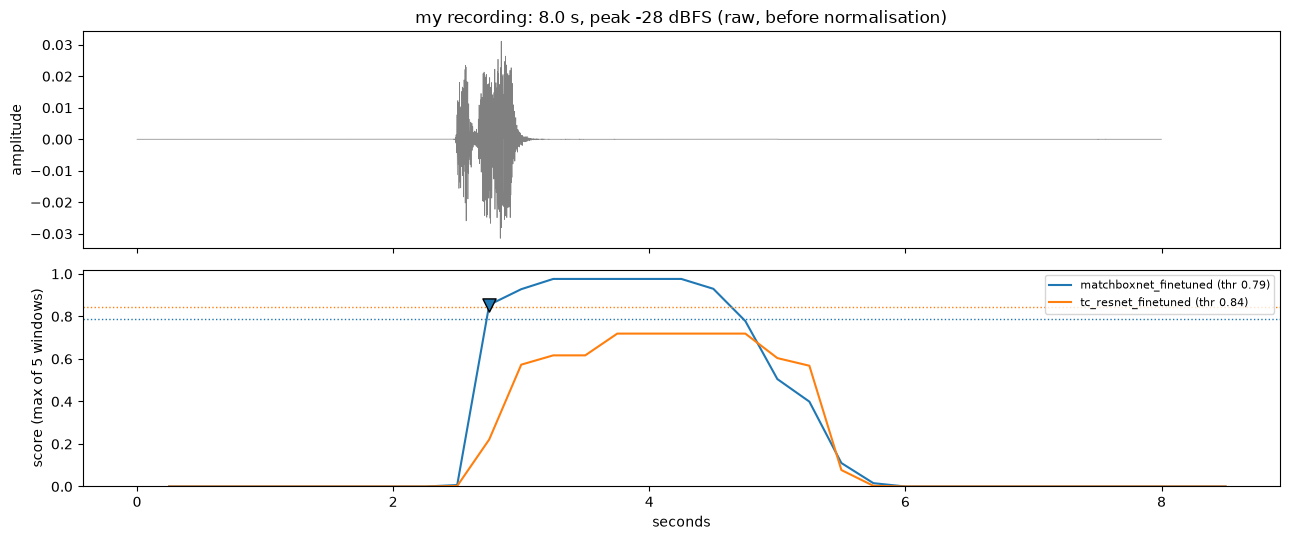

,fired,first_at_s,max_score,threshold
model,,,,
matchboxnet_finetuned,1,2.75,0.976,0.789
tc_resnet_finetuned,0,NaN,0.719,0.845


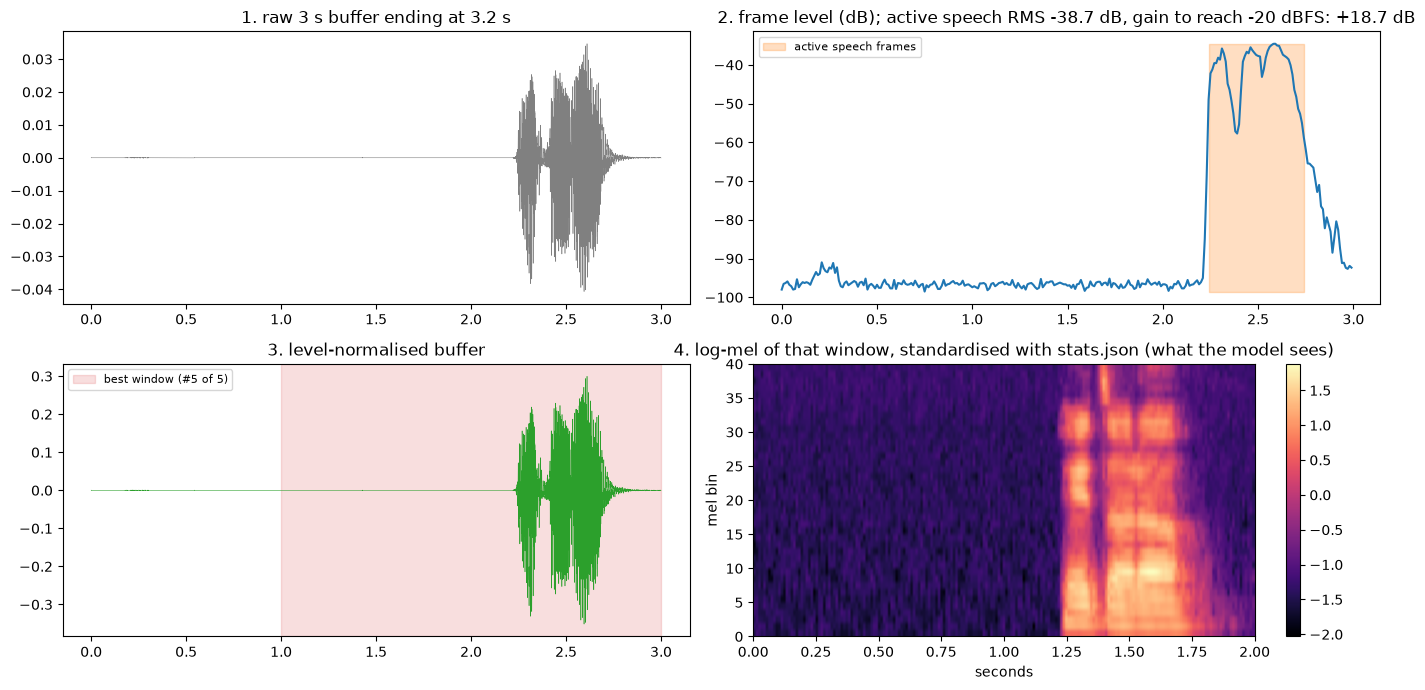

In [6]:
import sounddevice as sd

SECONDS = 8
INPUT_DEVICE = None          # None = system default microphone; or an index / name from sd.query_devices()

def record(seconds=8, device=INPUT_DEVICE):
    # records mono at 16 kHz straight from the microphone (no processing is applied by this code)
    print(f"RECORDING for {seconds} s: speak now ...")
    x = sd.rec(int(seconds * P.SR), samplerate=P.SR, channels=1, dtype="float32", device=device); sd.wait()
    print("done"); return x.reshape(-1)

# print(sd.query_devices())  # uncomment to list microphones and pick INPUT_DEVICE
my_audio = record(SECONDS); R, LR = analyse(my_audio, "my recording")

### Optional: test an audio file instead
If you want to try a recording you already have, set `TEST_WAV` to its path and run the cell.

In [ ]:
def load_audio(path):
    x, sr = sf.read(path, dtype="float32")
    if x.ndim > 1: x = x.mean(1)
    if sr != P.SR:
        from scipy.signal import resample_poly
        g = math.gcd(P.SR, sr); x = resample_poly(x, P.SR // g, sr // g).astype(np.float32)
    return x

TEST_WAV = None                                                      # e.g. "my_take.wav" (path to a local audio file readable by soundfile)
if TEST_WAV: R, LR = analyse(load_audio(TEST_WAV), Path(TEST_WAV).name)
else: print("set TEST_WAV to the path of a local audio file to analyse it")